<a href="https://colab.research.google.com/github/Sxryansh/Minor-Project/blob/main/Minor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI-Powered Student Performance Prediction System

This notebook develops an end-to-end machine learning system to predict student academic performance. We will start by generating a realistic synthetic dataset, performing Exploratory Data Analysis (EDA), training and evaluating three classification models, and finally implementing an interactive command-line interface to make predictions.

In [ ]:
# First Import Every Thing we are going to need

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score





In [ ]:

import pandas as pd

# Create the student performance dataset
data = {
    "Std.Name": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],

    "Attendance%": [
        81.8, 51.3, 86.5, 93.9, 75.1,
        88.7, 73.4, 85.7, 61.5, 81.6
    ],

    "Daily Study Hrs": [
        5.7, None, 2.7, 2.7, 2.0,
        4.5, 5.6, 0.7, 5.1, 1.9
    ],

    "Previous ExamMarks": [
        67.1, 61.9, 64.3, 87.8, None,
        68.9, 64.9, 60.3, 37.7, 79.6
    ],

    "Agn.Completion": [
        77.9, 100.0, 66.6, 88.4, None,
        68.6, 98.3, 50.7, 75.1, 73.9
    ],

    "Classoom Ptrp.": [
        8.4, 6.0, 3.4, 4.5, 7.7,
        4.6, 6.3, 7.7, None, 5.9
    ],

    "Subject": [
        "IT",
        "Mathematics",
        "Mathematics",
        "English",
        "Pol. Science",
        "Political Science",
        "Economics",
        "Geography",
        "English",
        "Political Science"
    ],

    "SubWise_Perform.": [
        68.8, 66.9, 75.5, None, 66.8,
        75.5, 93.6, None, 59.5, 73.3
    ],

    "Perform Cate.": [
        "Average", "Average", "Good", "Very Good",
        "Average", "Good", "Very Good", "Average",
        "Average", "Good"
    ]
}

# Convert data into a DataFrame
df = pd.DataFrame(data)

# Display the dataset
print("Student Performance Dataset")
display(df)

print("Dataset created and saved successfully!")


Student Performance Dataset


,Std.Name,Attendance%,Daily Study Hrs,Previous ExamMarks,Agn.Completion,Classoom Ptrp.,Subject,SubWise_Perform.,Perform Cate.
0,1,81.8,5.7,67.1,77.9,8.4,IT,68.8,Average
1,2,51.3,NaN,61.9,100.0,6.0,Mathematics,66.9,Average
2,3,86.5,2.7,64.3,66.6,3.4,Mathematics,75.5,Good
3,4,93.9,2.7,87.8,88.4,4.5,English,NaN,Very Good
4,5,75.1,2.0,NaN,NaN,7.7,Pol. Science,66.8,Average
5,6,88.7,4.5,68.9,68.6,4.6,Political Science,75.5,Good
6,7,73.4,5.6,64.9,98.3,6.3,Economics,93.6,Very Good
7,8,85.7,0.7,60.3,50.7,7.7,Geography,NaN,Average
8,9,61.5,5.1,37.7,75.1,NaN,English,59.5,Average
9,10,81.6,1.9,79.6,73.9,5.9,Political Science,73.3,Good


Dataset created and saved successfully!


#Data PreProcessing

In [ ]:
import numpy as np
import pandas as pd

print("Data Shape")
print(df.shape)

print("Data Shape")
print(df.shape)
print("Columns Name")
print(df.columns)
print("Data Types")
print(df.dtypes)
print("========================================================")
print("Duplicate records before removal:")
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Duplicate records after removal:")
print(df.duplicated().sum())
# Handle Missing Values

print("Missing values before handling:")
print(df.isnull().sum())

Data Shape
(10, 9)
Data Shape
(10, 9)
Columns Name
Index(['Std.Name', 'Attendance%', 'Daily Study Hrs', 'Previous ExamMarks',
       'Agn.Completion', 'Classoom Ptrp.', 'Subject', 'SubWise_Perform.',
       'Perform Cate.'],
      dtype='object')
Data Types
Std.Name                int64
Attendance%           float64
Daily Study Hrs       float64
Previous ExamMarks    float64
Agn.Completion        float64
Classoom Ptrp.        float64
Subject                object
SubWise_Perform.      float64
Perform Cate.          object
dtype: object
Duplicate records before removal:
0
Duplicate records after removal:
0
Missing values before handling:
Std.Name              0
Attendance%           0
Daily Study Hrs       1
Previous ExamMarks    1
Agn.Completion        1
Classoom Ptrp.        1
Subject               0
SubWise_Perform.      2
Perform Cate.         0
dtype: int64


In [ ]:
completerows = df.dropna()
print("Missing values after handling:")
print(completerows)


Missing values after handling:
   Std.Name  Attendance%  Daily Study Hrs  Previous ExamMarks  Agn.Completion  \
0         1         81.8              5.7                67.1            77.9   
1         2         51.3              2.7                61.9           100.0   
2         3         86.5              2.7                64.3            66.6   
3         4         93.9              2.7                87.8            88.4   
4         5         75.1              2.0                64.9            75.1   
5         6         88.7              4.5                68.9            68.6   
6         7         73.4              5.6                64.9            98.3   
7         8         85.7              0.7                60.3            50.7   
8         9         61.5              5.1                37.7            75.1   
9        10         81.6              1.9                79.6            73.9   

   Classoom Ptrp.            Subject  SubWise_Perform. Perform Cate.  
0     

In [ ]:
import pandas as pd

# Calculate mean and median from the DataFrame 'df'
mean_pym = df["Previous ExamMarks"].mean()
median_agn = df["Agn.Completion"].median()
mean_ptrp = df["Classoom Ptrp."].mean()
mean_subwise = df["SubWise_Perform."].mean()
mean_study = df["Daily Study Hrs"].mean()

# Filling Missing values using recommended pandas syntax (direct assignment)
df['Previous ExamMarks'] = df['Previous ExamMarks'].fillna(mean_pym)
df['Agn.Completion'] = df['Agn.Completion'].fillna(median_agn)
df['Classoom Ptrp.'] = df['Classoom Ptrp.'].fillna(mean_ptrp)
df['SubWise_Perform.'] = df['SubWise_Perform.'].fillna(mean_subwise)
df['Daily Study Hrs'] = df['Daily Study Hrs'].fillna(mean_study)

print("Missing values after handling:")
print(df.isnull().sum())

print("\nCleaned Dataset Preview:")
display(df.head())

Missing values after handling:
Std.Name              0
Attendance%           0
Daily Study Hrs       0
Previous ExamMarks    0
Agn.Completion        0
Classoom Ptrp.        0
Subject               0
SubWise_Perform.      0
Perform Cate.         0
dtype: int64

Cleaned Dataset Preview:


,Std.Name,Attendance%,Daily Study Hrs,Previous ExamMarks,Agn.Completion,Classoom Ptrp.,Subject,SubWise_Perform.,Perform Cate.
0,1,81.8,5.7,67.1,77.9,8.4,IT,68.80,Average
1,2,51.3,2.7,61.9,100.0,6.0,Mathematics,66.90,Average
2,3,86.5,2.7,64.3,66.6,3.4,Mathematics,75.50,Good
3,4,93.9,2.7,87.8,88.4,4.5,English,71.05,Very Good
4,5,75.1,2.0,64.9,75.1,7.7,Pol. Science,66.80,Average


In [ ]:
print("\nCleaned Dataset Preview:")
display(df.head())


Cleaned Dataset Preview:


,Std.Name,Attendance%,Daily Study Hrs,Previous ExamMarks,Agn.Completion,Classoom Ptrp.,Subject,SubWise_Perform.,Perform Cate.
0,1,81.8,5.7,67.1,77.9,8.4,IT,68.80,Average
1,2,51.3,2.7,61.9,100.0,6.0,Mathematics,66.90,Average
2,3,86.5,2.7,64.3,66.6,3.4,Mathematics,75.50,Good
3,4,93.9,2.7,87.8,88.4,4.5,English,71.05,Very Good
4,5,75.1,2.0,64.9,75.1,7.7,Pol. Science,66.80,Average


#Chart

Here is the complete dataset:


,Std.Name,Attendance%,Daily Study Hrs,Previous ExamMarks,Agn.Completion,Classoom Ptrp.,Subject,SubWise_Perform.,Perform Cate.
0,1,81.8,5.7,67.1,77.9,8.4,IT,68.8,Average
1,2,51.3,3.2,61.9,100.0,6.0,Mathematics,66.9,Average
2,3,86.5,2.7,64.3,66.6,3.4,Mathematics,75.5,Good
3,4,93.9,2.7,87.8,88.4,4.5,English,72.0,Very Good
4,5,75.1,2.0,65.0,75.0,7.7,Pol. Science,66.8,Average
5,6,88.7,4.5,68.9,68.6,4.6,Political Science,75.5,Good
6,7,73.4,5.6,64.9,98.3,6.3,Economics,93.6,Very Good
7,8,85.7,0.7,60.3,50.7,7.7,Geography,72.0,Average
8,9,61.5,5.1,37.7,75.1,6.0,English,59.5,Average
9,10,81.6,1.9,79.6,73.9,5.9,Political Science,73.3,Good


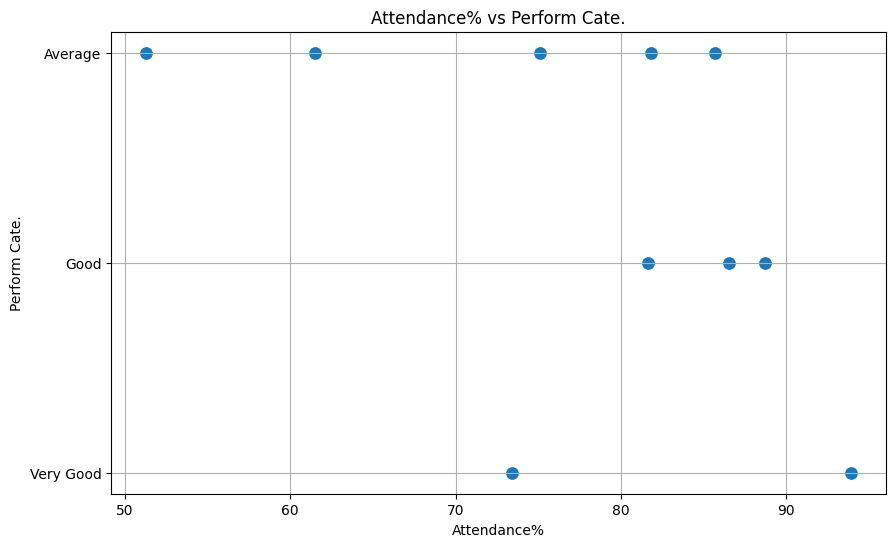

In [ ]:
# Display the entire dataset to inspect all rows
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

print("Here is the complete dataset:")
display(df)

import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Attendance%', y='Perform Cate.', s=100)
plt.xlabel('Attendance%')
plt.ylabel('Perform Cate.')
plt.title('Attendance% vs Perform Cate.')
plt.grid(True)
plt.show()

Bar chart

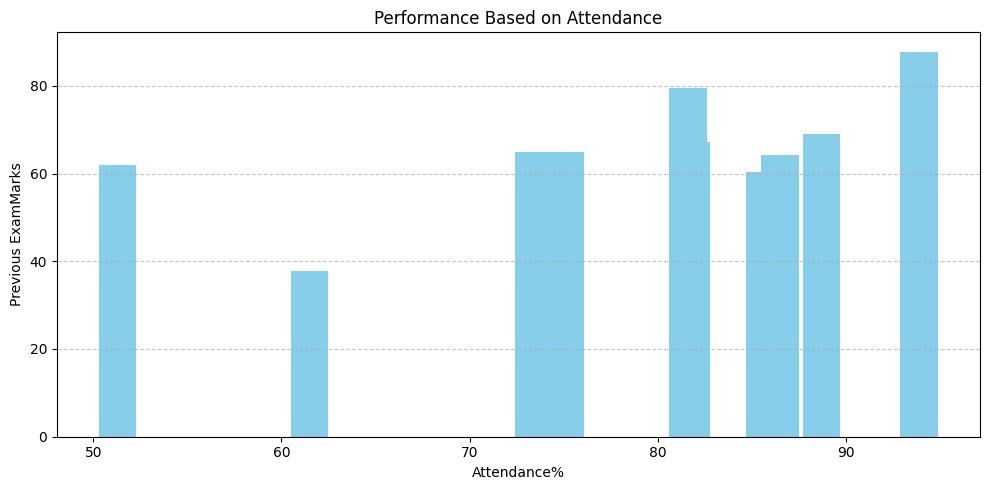

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(df["Attendance%"], df["Previous ExamMarks"], color='skyblue', width=2.0)
plt.xlabel("Attendance%")
plt.ylabel("Previous ExamMarks")
plt.title("Performance Based on Attendance")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

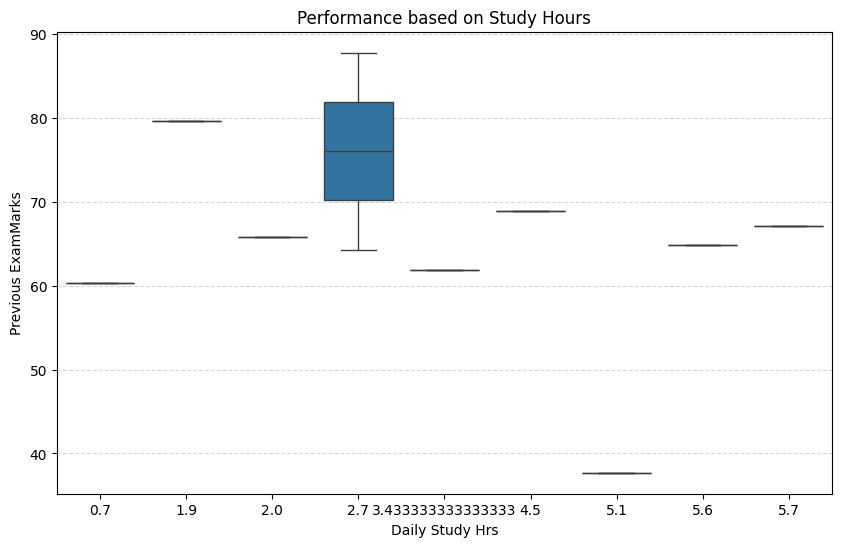

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

if 'df' not in globals() or 'Daily Study Hrs' not in df.columns:
    data = {
        "Std.Name": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
        "Attendance%": [81.8, 51.3, 86.5, 93.9, 75.1, 88.7, 73.4, 85.7, 61.5, 81.6],
        "Daily Study Hrs": [5.7, None, 2.7, 2.7, 2.0, 4.5, 5.6, 0.7, 5.1, 1.9],
        "Previous ExamMarks": [67.1, 61.9, 64.3, 87.8, None, 68.9, 64.9, 60.3, 37.7, 79.6],
        "Agn.Completion": [77.9, 100.0, 66.6, 88.4, None, 68.6, 98.3, 50.7, 75.1, 73.9],
        "Classoom Ptrp.": [8.4, 6.0, 3.4, 4.5, 7.7, 4.6, 6.3, 7.7, None, 5.9],
        "Subject": ["IT", "Mathematics", "Mathematics", "English", "Pol. Science", "Political Science", "Economics", "Geography", "English", "Political Science"],
        "SubWise_Perform.": [68.8, 66.9, 75.5, None, 66.8, 75.5, 93.6, None, 59.5, 73.3],
        "Perform Cate.": ["Average", "Average", "Good", "Very Good", "Average", "Good", "Very Good", "Average", "Average", "Good"]
    }
    df = pd.DataFrame(data)

    df['Previous ExamMarks'] = df['Previous ExamMarks'].fillna(df['Previous ExamMarks'].mean())
    df['Daily Study Hrs'] = df['Daily Study Hrs'].fillna(df['Daily Study Hrs'].mean())

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Daily Study Hrs', y='Previous ExamMarks')
plt.title("Performance based on Study Hours")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [22]:
from sklearn.model_selection import train_test_split

# Define features and target variable from the dataset
feature_cols = ['Attendance%', 'Daily Study Hrs', 'Previous ExamMarks', 'Agn.Completion']
x = df[feature_cols]
y = df['Perform Cate.']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("Training Data")
print(x_train)
print("Testing Data")
print(x_test)
print("===========================================")
print("Training Data")
print(y_train)
print("Testing Data")
print(y_test)

Training Data
   Attendance%  Daily Study Hrs  Previous ExamMarks  Agn.Completion
5         88.7              4.5           68.900000            68.6
0         81.8              5.7           67.100000            77.9
7         85.7              0.7           60.300000            50.7
2         86.5              2.7           64.300000            66.6
9         81.6              1.9           79.600000            73.9
4         75.1              2.0           65.833333             NaN
3         93.9              2.7           87.800000            88.4
6         73.4              5.6           64.900000            98.3
Testing Data
   Attendance%  Daily Study Hrs  Previous ExamMarks  Agn.Completion
8         61.5         5.100000                37.7            75.1
1         51.3         3.433333                61.9           100.0
Training Data
5         Good
0      Average
7      Average
2         Good
9         Good
4      Average
3    Very Good
6    Very Good
Name: Perform Cate., dt

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Impute any remaining NaNs in the split features to keep training stable
x_train_imputed = x_train.fillna(x_train.mean())
x_test_imputed = x_test.fillna(x_train.mean())

# Train a logistic regression model with basic settings
lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(x_train_imputed, y_train)

# Get predictions and check classification performance
y_pred = lr_model.predict(x_test_imputed)

print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("Detailed Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 1.0
Detailed Report:
              precision    recall  f1-score   support

     Average       1.00      1.00      1.00         2

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

# Standardize imputation for stable evaluation
x_train_imputed = x_train.fillna(x_train.mean())
x_test_imputed = x_test.fillna(x_train.mean())

# Initialize classifiers
dt_model = DecisionTreeClassifier(random_state=42)
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)

# Fit models
dt_model.fit(x_train_imputed, y_train)
rf_model.fit(x_train_imputed, y_train)

# Get predictions
dt_preds = dt_model.predict(x_test_imputed)
rf_preds = rf_model.predict(x_test_imputed)

# Gather metric comparisons
models = {
    "Logistic Regression": lr_model.predict(x_test_imputed),
    "Decision Tree": dt_preds,
    "Random Forest": rf_preds
}

comparison_data = []
for name, preds in models.items():
    acc = accuracy_score(y_test, preds)
    # Compute weighted averages for precision, recall, f1-score to handle small/unbalanced test split
    rep = classification_report(y_test, preds, output_dict=True, zero_division=0)
    comparison_data.append({
        "Model": name,
        "Accuracy": acc,
        "Precision (Weighted)": rep["weighted avg"]["precision"],
        "Recall (Weighted)": rep["weighted avg"]["recall"],
        "F1-Score (Weighted)": rep["weighted avg"]["f1-score"]
    })

# Display comparison table
comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Logistic Regression,1.0,1.0,1.0,1.000000
1,Decision Tree,0.5,1.0,0.5,0.666667
2,Random Forest,0.5,1.0,0.5,0.666667


In [32]:
def predict_student_performance():
    print("--- Student Performance Predictor ---")

    # Collect user inputs with fallback defaults based on our training averages
    try:
        attendance = input("Enter Attendance % (e.g. 85.5): ")
        attendance = float(attendance) if attendance.strip() else 80.0

        study_hours = input("Enter Daily Study Hours (e.g. 3.5): ")
        study_hours = float(study_hours) if study_hours.strip() else 3.0

        prev_marks = input("Enter Previous Exam Marks (e.g. 68.0): ")
        prev_marks = float(prev_marks) if prev_marks.strip() else 65.0

        agn_completion = input("Enter Assignment Completion % (e.g. 75.0): ")
        agn_completion = float(agn_completion) if agn_completion.strip() else 75.0
    except ValueError:
        print("Invalid numerical input. Using baseline average values instead.")
        attendance, study_hours, prev_marks, agn_completion = 80.0, 3.0, 65.0, 75.0

    # Structure input as a DataFrame matching the model's feature names
    input_data = pd.DataFrame([[attendance, study_hours, prev_marks, agn_completion]],
                              columns=['Attendance%', 'Daily Study Hrs', 'Previous ExamMarks', 'Agn.Completion'])

    # Predict using our trained logistic regression model
    prediction = lr_model.predict(input_data)[0]

    print("===================================")
    print(f"Predicted Performance Category: {prediction}")
    print("===================================")

# Run the interactive predictor
predict_student_performance()

--- Student Performance Predictor ---
Enter Attendance % (e.g. 85.5): 75
Enter Daily Study Hours (e.g. 3.5): 4
Enter Previous Exam Marks (e.g. 68.0): 74
Enter Assignment Completion % (e.g. 75.0): 70
Predicted Performance Category: Average
